# 미추홀구 I-MOD STEP 2 — K-Means 비교 및 후보 군집 해석

**분석 단위:** 286개 정류장명 기반 정류장군, 2026년 4~6월(6/11 제외 90일). 지도 좌표는 사용하지 않습니다.  
**분석 목적:** 변수 조합(A~D) × 규모 변수 로그변환 × 극단 이상치 영향 × K=3~8 비교.  
**원칙:** 결측을 0으로 채우지 않음. 노선 수 결측 2건은 중앙값 대체(별도 민감도 분석), 이상치는 기준 모델에서 유지, 군집 번호는 우열 순위가 아님.  

> **입력:** `03_features_expanded_286.csv` (STEP 1 결과, 권장) 또는 `01_StopGroup_Features_With_Routes_2026Q2.csv` + `04_StopGroup_Hourly_2026Q2.csv` (주말/평일 비율이 없을 때만).

In [1]:
import sys, subprocess, importlib.util
for pkg in ['pandas','numpy','scipy','sklearn','matplotlib','seaborn','openpyxl']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn' if pkg=='sklearn' else pkg])
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.impute import SimpleImputer
from IPython.display import display
import warnings, zipfile, json
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
OUT=Path('IMOD_STEP2_KMeans_Results'); OUT.mkdir(exist_ok=True)
plt.rcParams['axes.unicode_minus']=False
print('환경 준비 완료 / 출력 폴더:', OUT)

환경 준비 완료 / 출력 폴더: IMOD_STEP2_KMeans_Results


## 1. 파일 업로드 (중복 파일명도 인식)

**가장 쉬운 방법:** STEP 1에서 생성된 `03_features_expanded_286.csv` 하나만 업로드하세요. 다른 이름의 CSV를 올리면 필요한 열을 확인합니다.

In [2]:
import os
# Colab에서는 업로드한 실제 파일명을 그대로 사용. 로컬에서는 이미 있는 파일 자동 검색.
if 'google.colab' in sys.modules or 'COLAB_RELEASE_TAG' in os.environ:
    from google.colab import files
    print('STEP1 확장 Features 파일 하나를 업로드하세요. 필요한 경우 Hourly 파일도 업로드하세요.')
    uploaded=files.upload()
else:
    uploaded={}

def resolve(markers):
    paths=[]
    roots=[Path('.'),Path('/mnt/data/IMOD_EDA_Results'),Path('/mnt/data/IMOD_Route_Features_2026Q2'),Path('/mnt/data/IMOD_StopGroups_2026Q2')]
    for root in roots:
        if root.exists(): paths+=list(root.glob('*.csv'))
    for k in uploaded.keys(): paths.append(Path(k))
    # 가장 구체적인 파일 우선, 반복 업로드 suffix도 지원
    for marker in markers:
        matches=[p for p in paths if marker in p.name and p.exists()]
        if matches: return sorted(matches,key=lambda p:p.stat().st_mtime)[-1]
    return None

feature_path=resolve(['03_features_expanded_286','StopGroup_Features_With_Routes'])
if feature_path is None: raise FileNotFoundError('03_features_expanded_286.csv 또는 01_StopGroup_Features_With_Routes_2026Q2.csv를 업로드하세요.')
df=pd.read_csv(feature_path,encoding='utf-8-sig')
print('Features 경로:',feature_path,'형태:',df.shape)
if 'weekend_weekday_demand_ratio' not in df.columns:
    hp=resolve(['StopGroup_Hourly'])
    if hp is None:
        raise FileNotFoundError('현재 Features 파일에는 weekend_weekday_demand_ratio가 없습니다. 04_StopGroup_Hourly_2026Q2.csv도 업로드 후 이 셀을 다시 실행하세요. 또는 STEP1의 03_features_expanded_286.csv를 사용하세요.')
    h=pd.read_csv(hp,encoding='utf-8-sig',usecols=['station_name','date','passenger_count'])
    h['date']=pd.to_datetime(h['date'].astype(str).str.replace(r'\.0$','',regex=True), errors='coerce')
    if h['date'].isna().any():raise ValueError('Hourly 날짜 변환 오류')
    day=h.groupby(['station_name','date'],as_index=False)['passenger_count'].sum()
    day['is_weekend']=day['date'].dt.dayofweek>=5
    a=day.groupby(['station_name','is_weekend'])['passenger_count'].mean().unstack().reindex(columns=[False,True])
    r=(a[True]/a[False].replace(0,np.nan)).rename('weekend_weekday_demand_ratio')
    df=df.merge(r,left_on='station_name',right_index=True,how='left',validate='one_to_one')
    print('주말/평일 비율 재계산 완료:',hp)
if len(df)!=286 or df.station_name.nunique()!=286: raise ValueError(f'286개 정류장명을 기대했지만 현재 {len(df)}행 / 고유 {df.station_name.nunique()}개입니다.')
print('관측 대상 286개 확인 / 사용 변수 확인 준비')

STEP1 확장 Features 파일 하나를 업로드하세요. 필요한 경우 Hourly 파일도 업로드하세요.


Saving 03_features_expanded_286.csv to 03_features_expanded_286.csv
Features 경로: 03_features_expanded_286.csv 형태: (286, 34)
관측 대상 286개 확인 / 사용 변수 확인 준비


## 2. 변수 정의와 결측·이상치 진단

In [3]:
SETS={
 'A_기준5':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg'],
 'B_요일추가6':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio'],
 'C_노선추가7':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio','unique_route_count'],
 'D_CV대체7':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','demand_cv_hour_profile','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio','unique_route_count']}
ALL=list(dict.fromkeys(x for cols in SETS.values() for x in cols))
missing=[c for c in ALL if c not in df.columns]
if missing:raise ValueError('Features 파일에 필요한 변수가 없습니다: '+str(missing))
for c in ALL: df[c]=pd.to_numeric(df[c],errors='coerce')
if (df[ALL].drop(columns='weekend_weekday_demand_ratio',errors='ignore')<0).any().any():
    raise ValueError('비음수여야 하는 지표에 음수가 있습니다. 정의/전처리를 먼저 확인하세요.')
df[ALL]=df[ALL].replace([np.inf,-np.inf],np.nan)
display(df[ALL].isna().sum().to_frame('결측 수'))
print('고유 노선수 결측 정류장명:',df.loc[df.unique_route_count.isna(),'station_name'].tolist())
# IQR 기준 변수별 이상치 (분석에서는 자동 삭제하지 않음)
audit=[]
for c in ALL:
    s=df[c].dropna(); q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    lo,hi=q1-1.5*iqr,q3+1.5*iqr
    audit.append({'variable':c,'q1':q1,'q3':q3,'iqr':iqr,'outlier_count':int(((s<lo)|(s>hi)).sum()),'missing':int(df[c].isna().sum())})
audit=pd.DataFrame(audit)
display(audit)
audit.to_csv(OUT/'01_variable_quality.csv',index=False,encoding='utf-8-sig')

,결측 수
avg_daily_passengers,0
avg_daily_operations,0
passengers_per_operation,0
temporal_mismatch,0
low_supply_hour_ratio_lt1avg,0
weekend_weekday_demand_ratio,0
unique_route_count,2
demand_cv_hour_profile,0


고유 노선수 결측 정류장명: ['숭의역(2번출구)', '시민공원.문화창작지대']


,variable,q1,q3,iqr,outlier_count,missing
0,avg_daily_passengers,77.300000,540.650000,463.350000,23,0
1,avg_daily_operations,170.841667,673.438889,502.597223,10,0
2,passengers_per_operation,0.412474,1.128508,0.716034,11,0
3,temporal_mismatch,0.164496,0.248896,0.084401,15,0
4,low_supply_hour_ratio_lt1avg,0.166667,0.208333,0.041666,3,0
5,weekend_weekday_demand_ratio,0.515757,0.689964,0.174207,15,0
6,unique_route_count,2.000000,7.000000,5.000000,10,2
7,demand_cv_hour_profile,0.719750,0.965184,0.245434,16,0


## 3. 민감도 분석의 이상치 정의

전 변수의 IQR 이상치(정상적인 대형 정류장 포함)를 일괄 삭제하지 않습니다. **시간적 불일치가 극단적이며 일평균 승차량이 거의 없는 정류장**을 하나의 명시적 민감도 대상으로 정의합니다. 기본 시나리오는 286개 전부 유지하며, 제외 시나리오는 보조 비교용입니다.

In [4]:
# 사전 정의: 일평균 승차량 1명 미만 && temporal_mismatch >= 0.80
extreme_mask=(df['avg_daily_passengers']<1)&(df['temporal_mismatch']>=0.80)
print('민감도 비교용 극단 정류장 수:',extreme_mask.sum())
display(df.loc[extreme_mask,['station_name','avg_daily_passengers','temporal_mismatch']])
df.loc[extreme_mask,['station_name','avg_daily_passengers','temporal_mismatch']].to_csv(OUT/'02_extreme_outlier_audit.csv',index=False,encoding='utf-8-sig')
# 0개라면 전체/제외 비교가 동일해져도 허용: 임의의 정류장을 지우지 않음.

민감도 비교용 극단 정류장 수: 1


,station_name,avg_daily_passengers,temporal_mismatch
25,국제이노베이션,0.022222,0.863439


## 4. 4개 변수 조합 × 로그변환 여부 × 이상치 여부 × K=3~8

- 로그 변환: `avg_daily_passengers`, `avg_daily_operations`, `passengers_per_operation`, `unique_route_count`, `weekend_weekday_demand_ratio`에만 `log1p` (모두 비음수 확인 후)
- 중앙값 결측 대체는 **각 실험의 표본**에서 계산, 원본 `df`는 보존
- StandardScaler 표준화 후 K-Means (`random_state=42`, `n_init=10`)
- 전체 286개 시나리오가 기본; 소수 이상치 제외는 민감도 확인용

In [5]:
LOG_COLS={'avg_daily_passengers','avg_daily_operations','passengers_per_operation','unique_route_count','weekend_weekday_demand_ratio'}
experiments=[]; labels_cache={}; impute_records=[]
def matrix_for(subframe,cols,use_log):
    x=subframe[cols].copy()
    missing_before=x.isna().sum().to_dict()
    imp=SimpleImputer(strategy='median')
    x=pd.DataFrame(imp.fit_transform(x),columns=cols,index=x.index)
    if use_log:
        for c in cols:
            if c in LOG_COLS:
                if (x[c]<0).any(): raise ValueError(f'{c} 로그 적용 불가: 음수 존재')
                x[c]=np.log1p(x[c])
    x=StandardScaler().fit_transform(x)
    return x,missing_before

for set_name,cols in SETS.items():
    for log_flag in [False,True]:
        for outlier_flag in ['전체286','극단값제외']:
            subset=df if outlier_flag=='전체286' else df.loc[~extreme_mask]
            if len(subset)<10: continue
            x,mis=matrix_for(subset,cols,log_flag)
            for k in range(3,9):
                model=KMeans(n_clusters=k,random_state=SEED,n_init=10,max_iter=300)
                lab=model.fit_predict(x)
                sizes=pd.Series(lab).value_counts()
                key=(set_name,log_flag,outlier_flag,k)
                labels_cache[key]=pd.Series(lab,index=subset.index,name='cluster')
                experiments.append({'set':set_name,'log1p':log_flag,'outlier_policy':outlier_flag,'k':k,'n':len(subset),
                                    'silhouette':silhouette_score(x,lab),
                                    'davies_bouldin':davies_bouldin_score(x,lab),
                                    'inertia':model.inertia_,
                                    'min_cluster_size':int(sizes.min()),
                                    'max_cluster_size':int(sizes.max()),
                                    'singleton_clusters':int((sizes<=1).sum()),
                                    'small_clusters_lt5':int((sizes<5).sum()),
                                    'cluster_sizes':';'.join(map(str,sorted(sizes.tolist())))})
            impute_records.append({'set':set_name,'log1p':log_flag,'outlier_policy':outlier_flag,'n':len(subset),**{f'missing_{k}':v for k,v in mis.items()}})
results=pd.DataFrame(experiments)
results.to_csv(OUT/'03_all_experiments.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(impute_records).to_csv(OUT/'04_imputation_audit.csv',index=False,encoding='utf-8-sig')
print('실험 조합:',len(results),'개')
display(results.sort_values('silhouette',ascending=False).head(15))

실험 조합: 96 개


,set,log1p,outlier_policy,k,n,silhouette,davies_bouldin,inertia,min_cluster_size,max_cluster_size,singleton_clusters,small_clusters_lt5,cluster_sizes
30,B_요일추가6,False,극단값제외,3,285,0.322878,1.162939,1006.722355,19,193,0,0,19;73;193
42,B_요일추가6,True,극단값제외,3,285,0.313862,1.311302,940.557796,42,182,0,0,42;61;182
6,A_기준5,False,극단값제외,3,285,0.306440,1.109698,779.332671,9,183,0,0,9;93;183
4,A_기준5,False,전체286,7,286,0.305653,0.889649,424.141613,1,121,1,2,1;2;30;32;38;62;121
78,D_CV대체7,False,극단값제외,3,285,0.305602,1.180500,1157.602061,25,193,0,0,25;67;193
7,A_기준5,False,극단값제외,4,285,0.298939,1.112119,634.533972,3,169,0,1,3;48;65;169
54,C_노선추가7,False,극단값제외,3,285,0.298582,1.195710,1157.737505,25,187,0,0,25;73;187
1,A_기준5,False,전체286,4,286,0.293554,1.116049,648.823243,3,169,0,1,3;48;66;169
0,A_기준5,False,전체286,3,286,0.291786,1.119986,793.558587,7,177,0,0,7;102;177
5,A_기준5,False,전체286,8,286,0.291522,0.885687,370.701623,1,90,1,2,1;2;20;29;30;49;65;90


## 5. 평가 그래프: 실루엣과 최소 군집 크기 (전체 286개 기준)

/tmp/ipykernel_2229/2794644534.py:11: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.savefig(OUT/'05_silhouette_cluster_size.png',dpi=170,bbox_inches='tight');plt.show()
/tmp/ipykernel_2229/2794644534.py:11: UserWarning: Glyph 51456 (\N{HANGUL SYLLABLE JUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.savefig(OUT/'05_silhouette_cluster_size.png',dpi=170,bbox_inches='tight');plt.show()
/tmp/ipykernel_2229/2794644534.py:11: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.savefig(OUT/'05_silhouette_cluster_size.png',dpi=170,bbox_inches='tight');plt.show()
/tmp/ipykernel_2229/2794644534.py:11: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.savefig(OUT/'05_silhouette_cluster_size.png',dpi=170,bbox_inches='tight');plt.show()
/tmp/ipykernel_2229/2794644534.py:11: UserWarning: Glyph 52628 (\N{HANG

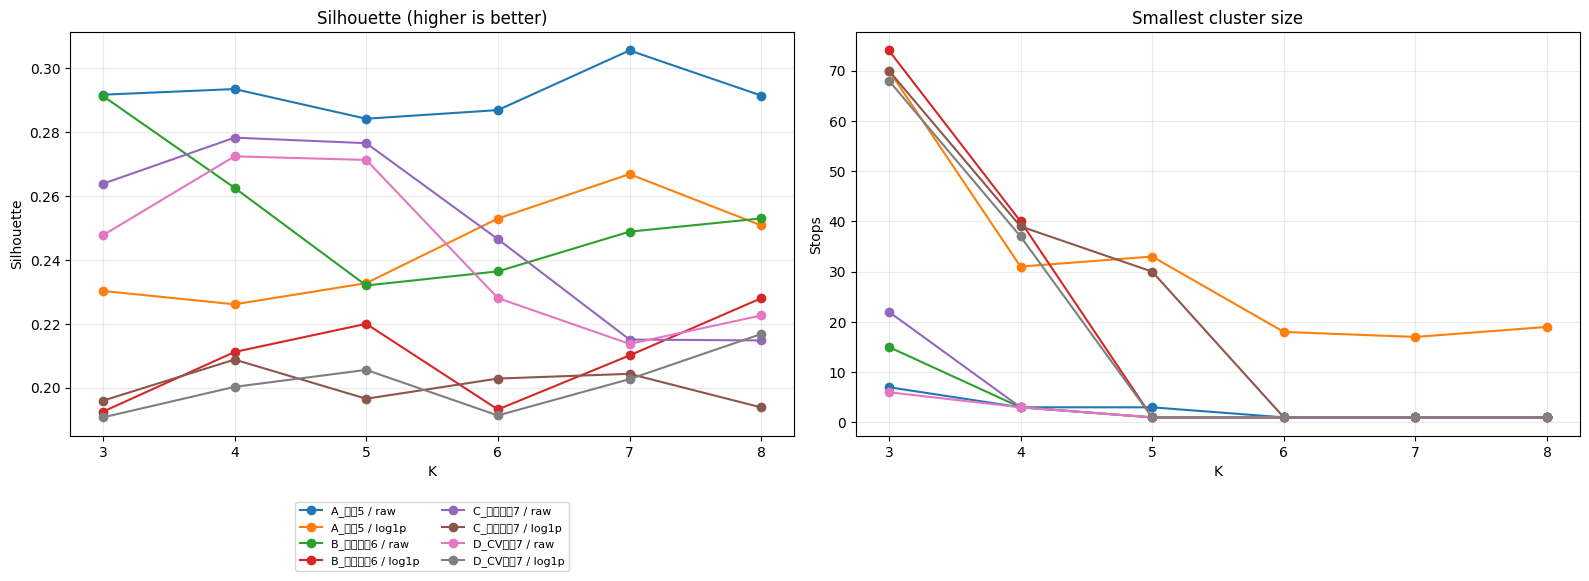

In [6]:
baseline=results[results.outlier_policy=='전체286'].copy()
fig,axes=plt.subplots(1,2,figsize=(16,6))
for (s,lg),g in baseline.groupby(['set','log1p']):
    label=s+(' / log1p' if lg else ' / raw')
    axes[0].plot(g.k,g.silhouette,marker='o',label=label)
    axes[1].plot(g.k,g.min_cluster_size,marker='o',label=label)
axes[0].set(title='Silhouette (higher is better)',xlabel='K',ylabel='Silhouette')
axes[1].set(title='Smallest cluster size',xlabel='K',ylabel='Stops')
for ax in axes: ax.grid(alpha=.25)
axes[0].legend(fontsize=8,bbox_to_anchor=(0.5,-.15),loc='upper center',ncol=2)
plt.tight_layout();plt.savefig(OUT/'05_silhouette_cluster_size.png',dpi=170,bbox_inches='tight');plt.show()
# 모델마다 전처리/변수 공간이 다르므로 inertia 값을 모델 간 직접 비교해서 우열 판단하면 안 됨.


## 6. 모델 선택: 점수만으로 선택하지 않기

최소 군집 5개 이상을 우선 만족시키고, 실루엣이 좋은 실험을 후보로 보여줍니다. **이는 자동 확정이 아닌 분석용 우선순위**입니다. 목표인 I-MOD와 군집의 의미 적합성까지 확인해야 합니다.

In [7]:
eligible=baseline[baseline.min_cluster_size>=5].copy()
if eligible.empty:
    print('최소 군집 5개 조건 충족 없음. 전체 결과에서 비교합니다.')
    eligible=baseline
ranked=eligible.sort_values(['silhouette','davies_bouldin'],ascending=[False,True])
display(ranked.head(12))
# 보고서에서 해석하기 쉬운 A 기준 모델과 '최고 실루엣' 참고 모델을 둘 다 산출
reference_key=('A_기준5',False,'전체286',3)
if reference_key not in labels_cache:raise RuntimeError('A기준 모델이 없습니다.')
recommended=ranked.iloc[0]
best_key=(recommended['set'],bool(recommended['log1p']),'전체286',int(recommended['k']))
print('기준 모델:',reference_key,' / 높은 분리도 후보:',best_key)


,set,log1p,outlier_policy,k,n,silhouette,davies_bouldin,inertia,min_cluster_size,max_cluster_size,singleton_clusters,small_clusters_lt5,cluster_sizes
0,A_기준5,False,전체286,3,286,0.291786,1.119986,793.558587,7,177,0,0,7;102;177
24,B_요일추가6,False,전체286,3,286,0.291375,1.241846,1066.459747,15,186,0,0,15;85;186
16,A_기준5,True,전체286,7,286,0.266901,1.179235,459.645417,17,93,0,0,17;20;23;29;42;62;93
48,C_노선추가7,False,전체286,3,286,0.263891,1.292025,1212.482983,22,170,0,0,22;94;170
15,A_기준5,True,전체286,6,286,0.252986,1.250400,513.096640,18,91,0,0,18;22;34;60;61;91
17,A_기준5,True,전체286,8,286,0.250834,1.123329,417.448515,19,56,0,0,19;22;24;28;39;44;54;56
72,D_CV대체7,False,전체286,3,286,0.247755,1.227201,1215.618538,6,160,0,0,6;120;160
14,A_기준5,True,전체286,5,286,0.232735,1.401363,572.054285,33,90,0,0,33;39;61;63;90
12,A_기준5,True,전체286,3,286,0.230299,1.379912,726.774979,70,134,0,0,70;82;134
13,A_기준5,True,전체286,4,286,0.226114,1.503441,644.975652,31,135,0,0,31;55;65;135


기준 모델: ('A_기준5', False, '전체286', 3)  / 높은 분리도 후보: ('A_기준5', False, '전체286', 3)


## 7. 기준 모델(A / 변환 없음 / K=3)과 분리도 후보 해석

In [8]:
def profile(key, prefix):
    lab=labels_cache[key]
    z=df.loc[lab.index,['station_name']+ALL].copy()
    z['cluster']=lab.to_numpy()
    # 원래 척도 값의 중앙값 및 평균 - 해석 가능성 보존
    med=z.groupby('cluster')[ALL].median().round(4)
    avg=z.groupby('cluster')[ALL].mean().round(4)
    size=z.groupby('cluster').size().rename('n')
    summary=med.join(size).sort_index()
    z.to_csv(OUT/f'{prefix}_assignments.csv',index=False,encoding='utf-8-sig')
    summary.to_csv(OUT/f'{prefix}_median_profile.csv',encoding='utf-8-sig')
    avg.to_csv(OUT/f'{prefix}_mean_profile.csv',encoding='utf-8-sig')
    display(summary)
    return z,summary
print('=== A 기준 모델 ===');baseline_assign,baseline_profile=profile(reference_key,'06_baseline_A_raw_K3')
print('=== 높은 분리도 후보 ===');best_assign,best_profile=profile(best_key,'07_best_candidate')


=== A 기준 모델 ===


,avg_daily_passengers,avg_daily_operations,passengers_per_operation,temporal_mismatch,low_supply_hour_ratio_lt1avg,weekend_weekday_demand_ratio,unique_route_count,demand_cv_hour_profile,n
cluster,,,,,,,,,
0,51.3444,141.0444,0.4033,0.2668,0.2083,0.5237,2.0,1.0062,102
1,4220.6000,1591.6111,3.5834,0.1754,0.1667,0.6349,17.0,0.6952,7
2,434.0222,560.8444,0.8579,0.1722,0.2083,0.6417,5.0,0.7465,177


=== 높은 분리도 후보 ===


,avg_daily_passengers,avg_daily_operations,passengers_per_operation,temporal_mismatch,low_supply_hour_ratio_lt1avg,weekend_weekday_demand_ratio,unique_route_count,demand_cv_hour_profile,n
cluster,,,,,,,,,
0,51.3444,141.0444,0.4033,0.2668,0.2083,0.5237,2.0,1.0062,102
1,4220.6000,1591.6111,3.5834,0.1754,0.1667,0.6349,17.0,0.6952,7
2,434.0222,560.8444,0.8579,0.1722,0.2083,0.6417,5.0,0.7465,177


## 8. 군집별 변수 특성 히트맵 / 군집 크기

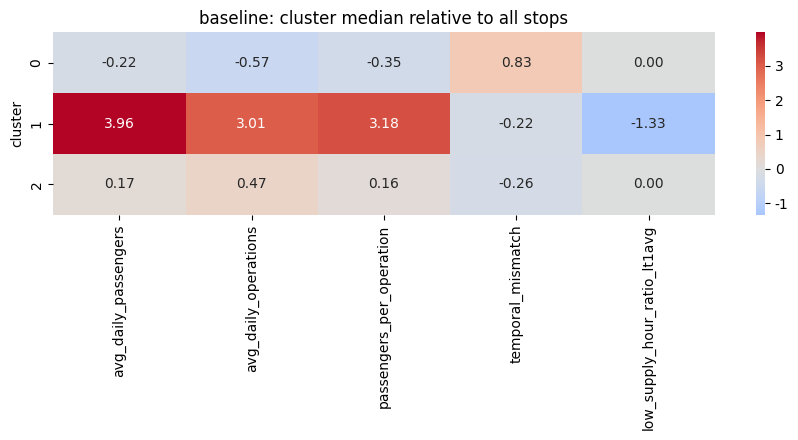

군집 크기: {0: 102, 1: 7, 2: 177}


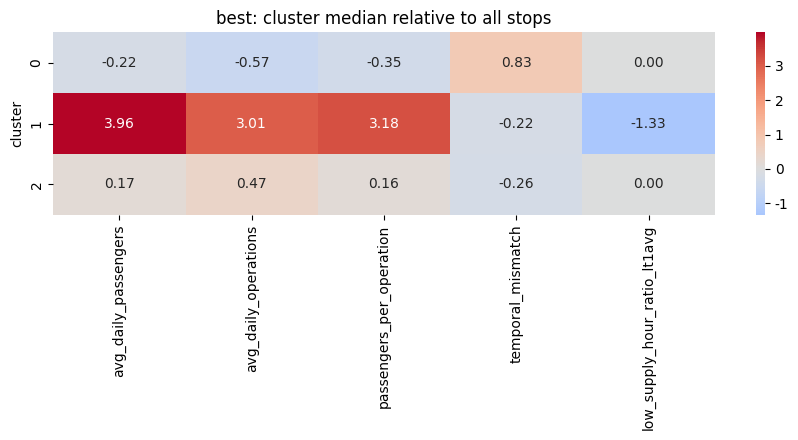

군집 크기: {0: 102, 1: 7, 2: 177}


In [9]:
def plot_cluster_profile(assign,prefix):
    cols=SETS[best_key[0]] if prefix=='best' else SETS['A_기준5']
    # 원본 척도 기준 정류장 286개 전체 중앙값/표준편차에 따른 설명용 변환
    grp=assign.groupby('cluster')[cols].median()
    den=df[cols].std(ddof=0).replace(0,np.nan)
    z=(grp-df[cols].median())/den
    fig,ax=plt.subplots(figsize=(max(9,len(cols)*1.6),4.5))
    sns.heatmap(z,annot=True,fmt='.2f',cmap='coolwarm',center=0,ax=ax)
    ax.set(title=f'{prefix}: cluster median relative to all stops')
    plt.tight_layout();plt.savefig(OUT/f'08_{prefix}_cluster_profile.png',dpi=170,bbox_inches='tight');plt.show()
    counts=assign.cluster.value_counts().sort_index()
    print('군집 크기:',counts.to_dict())
plot_cluster_profile(baseline_assign,'baseline')
plot_cluster_profile(best_assign,'best')


## 9. 모델 민감도: 이상치 영향과 로그변환 영향

동일한 정류장만 겹쳐 비교하여 ARI(Adjusted Rand Index)를 계산합니다. 군집 번호가 달라도 ARI는 일치도를 비교합니다. 주의: 극단값 제거 모델은 표본이 다르므로 교집합만 비교합니다.

In [10]:
rows=[]
for s in SETS:
    for k in range(3,9):
        base=labels_cache[(s,False,'전체286',k)]
        for typ,comp in [('raw_vs_log',labels_cache[(s,True,'전체286',k)]),
                         ('raw_vs_extreme_excluded',labels_cache[(s,False,'극단값제외',k)])]:
            ids=base.index.intersection(comp.index)
            rows.append({'set':s,'k':k,'comparison':typ,'shared_n':len(ids),
                         'ARI':adjusted_rand_score(base.loc[ids],comp.loc[ids])})
stability=pd.DataFrame(rows)
display(stability.head(15))
stability.to_csv(OUT/'09_sensitivity_ARI.csv',index=False,encoding='utf-8-sig')

,set,k,comparison,shared_n,ARI
0,A_기준5,3,raw_vs_log,286,0.419433
1,A_기준5,3,raw_vs_extreme_excluded,285,0.850446
2,A_기준5,4,raw_vs_log,286,0.441102
3,A_기준5,4,raw_vs_extreme_excluded,285,0.976613
4,A_기준5,5,raw_vs_log,286,0.532988
5,A_기준5,5,raw_vs_extreme_excluded,285,0.951099
6,A_기준5,6,raw_vs_log,286,0.488978
7,A_기준5,6,raw_vs_extreme_excluded,285,0.979110
8,A_기준5,7,raw_vs_log,286,0.506065
9,A_기준5,7,raw_vs_extreme_excluded,285,0.608711


## 10. 노선 수 결측 2건의 영향 (286개 유지 vs 284개만)

고유 노선 수가 없는 정류장 2개를 **결측으로 유지한 채**, 노선 포함 모델 C/D에서 중앙값으로 보정한 286개 모델과, 해당 2개를 제외한 284개 모델의 군집 일치도를 확인합니다. 284개는 최종 대상에서 제외하는 것이 아니라 민감도 비교용입니다.

In [11]:
route_rows=[]
for s in ['C_노선추가7','D_CV대체7']:
    cols=SETS[s]
    for k in range(3,9):
        b=labels_cache[(s,False,'전체286',k)]
        sub=df.loc[df.unique_route_count.notna()]
        x,_=matrix_for(sub,cols,False)
        comp=pd.Series(KMeans(n_clusters=k,random_state=SEED,n_init=10).fit_predict(x),index=sub.index)
        route_rows.append({'set':s,'k':k,'n_full':286,'n_matched':len(sub),
                           'ARI_imputed_vs_complete_cases':adjusted_rand_score(b.loc[sub.index],comp)})
route_sensitivity=pd.DataFrame(route_rows)
display(route_sensitivity)
route_sensitivity.to_csv(OUT/'10_route_missing_sensitivity.csv',index=False,encoding='utf-8-sig')

,set,k,n_full,n_matched,ARI_imputed_vs_complete_cases
0,C_노선추가7,3,286,284,1.000000
1,C_노선추가7,4,286,284,0.977350
2,C_노선추가7,5,286,284,0.966544
3,C_노선추가7,6,286,284,0.847401
4,C_노선추가7,7,286,284,0.968904
5,C_노선추가7,8,286,284,0.635683
6,D_CV대체7,3,286,284,0.399508
7,D_CV대체7,4,286,284,0.989031
8,D_CV대체7,5,286,284,0.989052
9,D_CV대체7,6,286,284,0.495895


## 11. 군집별 I-MOD 검토 후보 (탐색용)

K-Means 군집은 I-MOD 필요도 순위가 아닙니다. 참고용으로 시간 불일치가 큰 정류장 가운데 **일평균 수요가 전체 중앙값 이상**인 정류장만 추립니다. 운행 0은 실제 미운행을 확정하는 정보가 아닙니다.

In [12]:
threshold=df.avg_daily_passengers.median()
for label,assign in [('baseline',baseline_assign),('best',best_assign)]:
    cand=assign.loc[assign.avg_daily_passengers>=threshold].sort_values('temporal_mismatch',ascending=False)
    display(cand[['station_name','cluster','avg_daily_passengers','avg_daily_operations','temporal_mismatch','low_supply_hour_ratio_lt1avg']].head(15))
    cand.to_csv(OUT/f'11_{label}_high_mismatch_demand_screen.csv',index=False,encoding='utf-8-sig')
print('수요 스크리닝 기준(전체 중앙값):',threshold)


,station_name,cluster,avg_daily_passengers,avg_daily_operations,temporal_mismatch,low_supply_hour_ratio_lt1avg
69,문학경기장(야구장),0,309.477778,456.133333,0.411426,0.208333
18,관교여자중학교,2,465.300000,560.844444,0.362473,0.166667
20,관교중학교(약수터),2,414.955556,560.744444,0.315564,0.166667
92,상수도사업본부(스마트타운),2,298.866667,1326.966667,0.282664,0.208333
204,인하대정문,2,1094.655556,1499.866667,0.268539,0.125000
285,힐스테이트학익104동앞,2,351.211111,770.644444,0.250140,0.208333
274,한국아파트,2,434.022222,941.922222,0.249245,0.125000
167,용현고가교,2,415.733333,636.500000,0.248705,0.208333
205,인하대후문,1,2666.888889,679.611111,0.247174,0.166667
191,인천의료원,2,309.655556,750.366667,0.247072,0.166667


,station_name,cluster,avg_daily_passengers,avg_daily_operations,temporal_mismatch,low_supply_hour_ratio_lt1avg
69,문학경기장(야구장),0,309.477778,456.133333,0.411426,0.208333
18,관교여자중학교,2,465.300000,560.844444,0.362473,0.166667
20,관교중학교(약수터),2,414.955556,560.744444,0.315564,0.166667
92,상수도사업본부(스마트타운),2,298.866667,1326.966667,0.282664,0.208333
204,인하대정문,2,1094.655556,1499.866667,0.268539,0.125000
285,힐스테이트학익104동앞,2,351.211111,770.644444,0.250140,0.208333
274,한국아파트,2,434.022222,941.922222,0.249245,0.125000
167,용현고가교,2,415.733333,636.500000,0.248705,0.208333
205,인하대후문,1,2666.888889,679.611111,0.247174,0.166667
191,인천의료원,2,309.655556,750.366667,0.247072,0.166667


수요 스크리닝 기준(전체 중앙값): 266.811111


## 12. 결과 압축·다운로드

In [13]:
report={
  'n_stops':int(len(df)), 'total_experiments':int(len(results)),
  'route_missing':int(df.unique_route_count.isna().sum()),
  'extreme_mask_count':int(extreme_mask.sum()),
  'baseline':str(reference_key),'silhouette_best_eligible':str(best_key),
  'method':'KMeans random_state=42 n_init=10 StandardScaler, with explicit imputation/log/outlier sensitivity',
  'caution':'High silhouette is not proof of transit shortage or I-MOD feasibility.'}
(OUT/'12_run_summary.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
zp=Path('Michuhol_IMOD_STEP2_KMeans_2026Q2_Results.zip')
with zipfile.ZipFile(zp,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.glob('*'):z.write(p,arcname=p.name)
print('저장 완료:',zp,'파일 수:',len(list(OUT.glob('*'))))
if 'google.colab' in sys.modules or 'COLAB_RELEASE_TAG' in os.environ:
    from google.colab import files
    files.download(str(zp))

저장 완료: Michuhol_IMOD_STEP2_KMeans_2026Q2_Results.zip 파일 수: 18


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 보고서 작성 시 주의사항
- 이 군집화는 **수요·공급 패턴의 유형화**이지 실제 I-MOD 공급 부족 증명이 아닙니다.
- 승차량, 운행횟수, 노선 수는 의미가 달라 높은 상관관계만으로 삭제하지 않습니다.
- 군집별 크기가 작거나 민감도 ARI가 낮으면 결과 안정성에 주의해야 합니다.
- 286개 전체를 기준 결과로 제시하고, 이상치 제거/결측 제거는 오직 민감도 실험으로 분리합니다.
- 최종 후보 권역은 이후 월별 반복성, 공간 타당성, 외부 검증으로 결정합니다.